Eigenvalues: [3. 1.]
Eigenvectors:
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


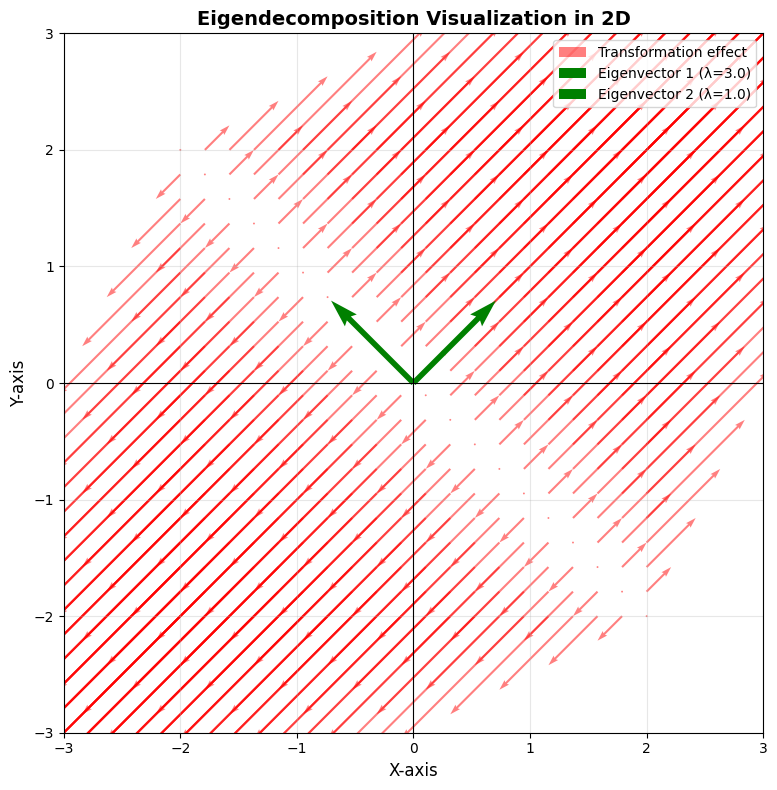


=== Eigendecomposition Summary ===
Matrix A:
[[2 1]
 [1 2]]

Eigenvalue 1: 3.0000
Eigenvector 1: [0.70710678 0.70710678]

Eigenvalue 2: 1.0000
Eigenvector 2: [-0.70710678  0.70710678]

Interpretation:
- Green arrows show eigenvector directions
- Eigenvalues show how much the transformation stretches/shrinks along each eigenvector
- Red arrows show how the transformation affects the grid points


In [6]:
import numpy as np                       # For numerical operations and linear algebra
import matplotlib.pyplot as plt          # For plotting and visualization

# Define the matrix A (2x2 matrix for 2D transformation)
A = np.array([[2, 1],                   # First row of matrix A
              [1, 2]])                  # Second row of matrix A
# This matrix represents a linear transformation in 2D space

# Compute eigenvalues and eigenvectors using numpy
eigenvalues, eigenvectors = np.linalg.eig(A)
# np.linalg.eig(): Computes eigenvalues and eigenvectors
# eigenvalues: array of eigenvalues (λ values where Av = λv)
# eigenvectors: matrix where each column is an eigenvector

print("Eigenvalues:", eigenvalues)      # Print the eigenvalues
print("Eigenvectors:\n", eigenvectors)  # Print the eigenvectors (each column is one eigenvector)

# Create a grid of points to visualize the transformation
x = np.linspace(-2, 2, 20)              # Create 20 points from -2 to 2 on x-axis
y = np.linspace(-2, 2, 20)              # Create 20 points from -2 to 2 on y-axis
X, Y = np.meshgrid(x, y)                # Create 2D grid: X and Y are (20, 20) arrays
                                        # meshgrid creates coordinate matrices from coordinate vectors

points = np.vstack([X.ravel(), Y.ravel()])
# X.ravel(): Flatten X into 1D array
# Y.ravel(): Flatten Y into 1D array
# vstack: Stack arrays vertically
# Result: points is (2, 400) - each column is a 2D point

# Apply the matrix transformation A to all points
transformed = A @ points                # Matrix multiplication: A × points
                                        # @ operator: matrix multiplication
                                        # Shape: (2, 2) @ (2, 400) = (2, 400)
                                        # Each point gets transformed by matrix A

# Create visualization
plt.figure(figsize=(10, 8))             # Create figure with size 10x8 inches

# Plot transformation vectors (from original to transformed points)
plt.quiver(points[0], points[1],        # Starting points (x, y)
           transformed[0]-points[0],    # Change in x (Δx)
           transformed[1]-points[1],    # Change in y (Δy)
           angles='xy',                 # Interpret angles in xy-plane
           scale_units='xy',            # Use xy units for scaling
           scale=1,                     # Scale factor (1 = no scaling)
           color='red',           # Color of arrows
           alpha=0.5,                   # Transparency (50%)
           label='Transformation effect')  # Label for legend

# Plot eigenvectors as arrows from origin
origin = np.zeros((2, 1))               # Origin point (0, 0)
                                        # Shape: (2, 1) for broadcasting

for i in range(len(eigenvalues)):      # Loop through each eigenvector
    plt.quiver(*origin,                 # Start at origin (0, 0)
               *eigenvectors[:, i],     # Direction (eigenvector components)
               angles='xy',             # Interpret angles in xy-plane
               scale_units='xy',        # Use xy units for scaling
               scale=1,                 # No scaling
               color='green',           # Color of eigenvector arrows
               width=0.008,             # Width of arrows
               label=f'Eigenvector {i+1} (λ={eigenvalues[i]:.1f})')
    # Label shows eigenvector number and its eigenvalue
    # f-string with .1f formats eigenvalue to 1 decimal place

# Add styling to the plot
plt.axhline(0, color='black', linewidth=0.8)  # Horizontal axis line at y=0
plt.axvline(0, color='black', linewidth=0.8)  # Vertical axis line at x=0

# Set axis limits
plt.xlim(-3, 3)                         # X-axis range: -3 to 3
plt.ylim(-3, 3)                         # Y-axis range: -3 to 3

# Set equal aspect ratio (square plot)
plt.gca().set_aspect('equal')           # gca(): get current axes
                                        # set_aspect('equal'): make x and y scales equal

# Add title and labels
plt.title("Eigendecomposition Visualization in 2D", fontsize=14, fontweight='bold')
plt.xlabel("X-axis", fontsize=12)       # Label for x-axis
plt.ylabel("Y-axis", fontsize=12)       # Label for y-axis

# Add legend and grid
plt.legend(loc='upper right')           # Show legend in upper right corner
plt.grid(True, alpha=0.3)               # Add grid with 30% transparency

# Adjust layout and display
plt.tight_layout()                      # Adjust spacing to prevent label cutoff
plt.show()                              # Display the plot

# Print summary information
print("\n=== Eigendecomposition Summary ===")
print(f"Matrix A:")
print(A)
print(f"\nEigenvalue 1: {eigenvalues[0]:.4f}")
print(f"Eigenvector 1: {eigenvectors[:, 0]}")
print(f"\nEigenvalue 2: {eigenvalues[1]:.4f}")
print(f"Eigenvector 2: {eigenvectors[:, 1]}")
print("\nInterpretation:")
print("- Green arrows show eigenvector directions")
print("- Eigenvalues show how much the transformation stretches/shrinks along each eigenvector")
print("- Red arrows show how the transformation affects the grid points")